# APM_50441_EP - Machine Learning 2 - Lab 3 (companion notebook): AutoGluon

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC3/APM_50441_EP_Lab_3_AutoGluon_simplified_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This short notebook complements the *To go further* part of Lab 3 with AutoGluon, an AutoML framework for tabular data. Its goals are:
- to run AutoGluon with a small time budget, and to read its leaderboard,
- to understand what it does inside: bagging, stacking and weighted ensembles,
- to use tabular foundation models (TabICLv2, TabDPT) through AutoGluon,
- to compare all these models with models of Lab 3, on the cost-based gain of Lab 1.

It takes about $20$ minutes with a GPU, and longer on a CPU.

We use `Python` with `autogluon.tabular`, `scikit-learn` and `polars`.

**Working environment.** Colab is the simplest option: open this notebook from the course repository (*Open in Colab* link), choose a GPU runtime (*Runtime > Change runtime type*) and run it. To work on your own computer, download the folder of Lab 3 (this notebook, the data and `apm_credit.py`) or clone the course repository, and use a *separate* environment, as AutoGluon pins many packages: create it once with [`uv`](https://docs.astral.sh/uv/) (`uv venv .venv-autogluon`, activate it with `source .venv-autogluon/bin/activate`, or `.venv-autogluon\Scripts\activate` on Windows, and `uv pip install jupyter`), then select it as the kernel of the notebook in your IDE (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). The installation cell below installs AutoGluon into the Python running the notebook; with an NVIDIA GPU, add `--torch-backend=auto` to it to get the CUDA version of PyTorch. TabDPT needs a GPU; the other models also run on a CPU, more slowly.

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

AutoGluon and its dependencies are installed at once (a few minutes). On Colab, restart the session once after this installation; locally, restart the kernel if the installation upgraded a package that was already loaded.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "autogluon.tabular[all,tabicl,tabdpt]==1.6.2" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "fairlearn==0.14.0"

Using Python 3.12.14 environment at: ~\.venvs\apm50441_autogluon
Checked 5 packages in 270ms


We use the German credit data and the cost model of Lab 1 (`apm_credit.py`), with the same split as Lab 3. Each file is downloaded only if there is no local copy.

In [3]:
import os
import urllib.request

# each file is downloaded only if there is no local copy
CSV_URL = "https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv"
APM_CREDIT_URL = "https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/common/apm_credit.py"  # course repository
for url in [CSV_URL, APM_CREDIT_URL]:
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    urllib.request.urlretrieve(url, filename)

In [4]:
import time, tempfile, warnings
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn.objects as so
from sklearn.model_selection import train_test_split
import apm_credit
from apm_credit import cost_metric, cost_predict_from_single_proba
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm without ipywidgets

german_credit = pl.read_csv("german_credit_data_biased_training.csv")
X = german_credit.drop('Risk')
y = german_credit['Risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
LoanAmount_test = X_test['LoanAmount']
apm_credit.set_proportions(y_train, {'Risk': .02, 'No Risk': .98})
train_data = X_train.with_columns(y_train).to_pandas()  # AutoGluon works on pandas data frames, with the label
test_data = X_test.to_pandas()
test_probas, fit_times = {}, {}  # test probabilities of Risk and fit times of the models, for the final summary

def test_gain(proba_risk):
  # real-world gain of the Bayes decision computed from the probabilities of Risk (Lab 1)
  return -cost_metric(y_test, cost_predict_from_single_proba(np.asarray(proba_risk), LoanAmount_test), LoanAmount_test)

As references, we fit two models of Lab 3 on the same data: a logistic regression and a histogram gradient boosting, with the preprocessing of Lab 3.

In [5]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
preprocessor = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), X.select(cs.string()).columns),
                                  ('num', StandardScaler(), X.select(cs.numeric()).columns)])
for name, model in {'logistic regression': LogisticRegression(max_iter=1000),
                    'gradient boosting': HistGradientBoostingClassifier(random_state=0)}.items():
  start = time.perf_counter()
  fitted = make_pipeline(clone(preprocessor), model).fit(X_train, y_train)
  fit_times[name] = time.perf_counter() - start
  test_probas[name] = fitted.predict_proba(X_test)[:, list(fitted.classes_).index('Risk')]
{name: round(test_gain(proba), 2) for name, proba in test_probas.items()}

{'logistic regression': 94.48, 'gradient boosting': 95.52}

## 1. AutoGluon in three minutes

`TabularPredictor` takes a data frame with the label, an evaluation metric and a time budget. With the preset `medium_quality`, it holds out a validation set, trains several kinds of models one after the other (LightGBM, CatBoost, XGBoost, random forests, extra trees, neural networks...) until the budget is spent, and combines them in a weighted ensemble. We use the log loss, as our decision relies on the probabilities. The models are written in a temporary folder.

**Question** Run `TabularPredictor(label='Risk', eval_metric='log_loss')` with `presets='medium_quality'` and `time_limit=180`, compute the test gain of the Bayes decision on its probabilities, and compare it with the two reference models. Look at its leaderboard: which models were trained, how long did they take, which one is the best on the validation set?

**Answer**

In [6]:
from autogluon.tabular import TabularPredictor
start = time.perf_counter()
predictor = TabularPredictor(label='Risk', eval_metric='log_loss', path=tempfile.mkdtemp(), verbosity=0).fit(
    train_data, presets='medium_quality', time_limit=180)
fit_times['AutoGluon'] = time.perf_counter() - start
test_probas['AutoGluon'] = predictor.predict_proba(test_data)['Risk'].to_numpy()
print(f"fit: {fit_times['AutoGluon']:.0f} s, best model: {predictor.model_best}, test gain: {test_gain(test_probas['AutoGluon']):.2f}")
predictor.leaderboard(silent=True)[['model', 'score_val', 'fit_time', 'pred_time_val', 'stack_level']]

fit: 208 s, best model: WeightedEnsemble_L2, test gain: 96.91


,model,score_val,fit_time,pred_time_val,stack_level
0,WeightedEnsemble_L2,-0.418971,151.254313,0.343947,2
1,NeuralNetFastAI,-0.429764,16.434078,0.043700,1
2,CatBoost,-0.432202,132.942105,0.044630,1
3,LightGBMXT,-0.434302,4.091616,0.031996,1
4,ExtraTreesGini,-0.437601,1.842273,0.253066,1
5,LightGBM,-0.439114,4.690443,0.037123,1
6,ExtraTreesEntr,-0.440391,1.867782,0.264640,1
7,RandomForestGini,-0.441638,2.218573,0.220980,1
8,RandomForestEntr,-0.443221,1.771442,0.218812,1
9,XGBoost,-0.446898,1.880756,0.040389,1


**Conclusion** AutoGluon spends its budget training about ten models: boosting libraries (LightGBM, CatBoost, XGBoost), random forests and extra trees, and neural networks. On the validation set, the best single models are the neural network of fastai and CatBoost (log loss $0.430$ and $0.432$), and the weighted ensemble of the best ones is better than all of them (about $0.42$). Its test gain (about $96$ to $97$: the models trained within the budget depend on the speed of the machine, so the result changes from one run to another) is above the two reference models of Lab 3 ($94.5$ for the logistic regression, $95.5$ for the gradient boosting), for a fit about $100$ times longer than the gradient boosting.

---

## 2. Inside AutoGluon: bagging and stacking

With `num_bag_folds=k`, each model is *bagged*: it is trained $k$ times on $k-1$ folds and predicts the remaining fold, which gives out-of-fold predictions on the whole training set (as in a cross validation), and the $k$ models are averaged. With `num_stack_levels=1`, a second layer of models is trained on the original features *and* the out-of-fold predictions of the first layer: this is *stacking* (Lecture 3, and the `StackingClassifier` of Lab 3). The final `WeightedEnsemble` averages the best models, with weights chosen greedily on the out-of-fold predictions (ensemble selection).

**Question** Fit AutoGluon again with `num_bag_folds=5`, `num_stack_levels=1`, `dynamic_stacking=False` and `time_limit=300`. In the leaderboard, identify the models of each layer (`stack_level`) and the final ensemble, and print the weights of the ensemble (with the internal function `predictor._trainer.load_model(predictor.model_best)._get_model_weights()`). Is the test gain better?

**Answer**

In [7]:
start = time.perf_counter()
stacked = TabularPredictor(label='Risk', eval_metric='log_loss', path=tempfile.mkdtemp(), verbosity=0).fit(
    train_data, presets='medium_quality', num_bag_folds=5, num_stack_levels=1, dynamic_stacking=False, time_limit=300)
fit_times['AutoGluon stacked'] = time.perf_counter() - start
test_probas['AutoGluon stacked'] = stacked.predict_proba(test_data)['Risk'].to_numpy()
print(f"fit: {fit_times['AutoGluon stacked']:.0f} s, best model: {stacked.model_best}, "
      f"test gain: {test_gain(test_probas['AutoGluon stacked']):.2f}")
print('weights of the final ensemble:', {name: round(float(w), 3) for name, w in
                                         stacked._trainer.load_model(stacked.model_best)._get_model_weights().items()})
stacked.leaderboard(silent=True)[['model', 'score_val', 'fit_time', 'stack_level']]

2026-10-14 13:28:08,630	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


fit: 320 s, best model: WeightedEnsemble_L3, test gain: 95.90
weights of the final ensemble: {'CatBoost_BAG_L1': 0.261, 'LightGBM_BAG_L2': 0.174, 'RandomForestGini_BAG_L2': 0.261, 'RandomForestEntr_BAG_L2': 0.174, 'CatBoost_BAG_L2': 0.13}


,model,score_val,fit_time,stack_level
0,WeightedEnsemble_L3,-0.413147,149.264172,3
1,CatBoost_BAG_L2,-0.417651,137.709106,2
2,WeightedEnsemble_L2,-0.419592,87.743598,2
3,CatBoost_BAG_L1,-0.420042,81.145217,1
4,LightGBMXT_BAG_L2,-0.420699,104.724256,2
5,LightGBM_BAG_L2,-0.421192,104.032825,2
6,RandomForestGini_BAG_L2,-0.424269,98.205172,2
7,LightGBMXT_BAG_L1,-0.426395,4.759569,1
8,RandomForestEntr_BAG_L2,-0.426716,98.097596,2
9,LightGBM_BAG_L1,-0.435420,6.809174,1


**Conclusion** With bagging and stacking, each model of the first layer (`_BAG_L1`) is trained $5$ times, one per fold; a second layer of models (`_BAG_L2`) is trained on the original features and the out-of-fold predictions of the first one, and the weighted ensembles combine the first layer (`WeightedEnsemble_L2`) and both layers (`WeightedEnsemble_L3`). The final ensemble mixes models of both layers, CatBoost and the random forests having the largest weights (the weights change from one run to another). Its validation log loss is a little better ($0.413$), as the out-of-fold predictions use the whole training set, but its test gain is not (about $96$): on $4000$ loans, stacking brings little, while the budget is spent on $5$ times more models, and the final model is much larger to store and slower to evaluate.

---

## 3. Tabular foundation models through AutoGluon

TabICLv2 and TabDPT are pretrained transformers: they do not fit parameters on our data, but use the training set as a *context* to predict the test points (in-context learning, Lecture 3). AutoGluon gives access to them with `hyperparameters={'TABICL': {}}` or `{'TABDPT': {}}`. With `refit_full=True`, the final model uses the whole training set as context, instead of the part left after the validation split. TabDPT needs a GPU; TabICLv2 also runs on a CPU, more slowly.

**Question** Fit TabICLv2 and TabDPT through AutoGluon (`time_limit=600`, `refit_full=True`, `set_best_to_refit_full=True`), and compare their test gains and their fit and prediction times with the other models.

**Answer**

In [8]:
import gc
import torch
del predictor, stacked  # AutoGluon skips the models that do not fit in the available memory: free the previous ones
gc.collect()
foundation_models = {'TabICLv2': 'TABICL', 'TabDPT': 'TABDPT'}
if not torch.cuda.is_available():
  print('No GPU: TabDPT is skipped')
  del foundation_models['TabDPT']
for name, key in foundation_models.items():
  start = time.perf_counter()
  model = TabularPredictor(label='Risk', eval_metric='log_loss', path=tempfile.mkdtemp(), verbosity=0).fit(
      train_data, hyperparameters={key: {}}, time_limit=600, refit_full=True, set_best_to_refit_full=True,
      # AutoGluon skips a model when its (conservative) memory estimate exceeds the free memory: these models work on the GPU
      ag_args_fit={'ag.max_memory_usage_ratio': 2})
  fit_times[name] = time.perf_counter() - start
  start = time.perf_counter()
  test_probas[name] = model.predict_proba(test_data)['Risk'].to_numpy()
  print(f'{name}: fit {fit_times[name]:.0f} s, prediction {time.perf_counter() - start:.0f} s, test gain {test_gain(test_probas[name]):.2f}')

TabICLv2: fit 13 s, prediction 3 s, test gain 98.02


TabDPT: fit 22 s, prediction 8 s, test gain 98.42


**Conclusion** TabICLv2 and TabDPT need no training on our data: their fit (about $15$ to $25$ s with the GPU) is mostly loading the pretrained weights and predicting the validation set, and they predict the $1000$ test loans in a few seconds. They give the best test gains of the notebook ($98.0$ and $98.4$), above the AutoGluon ensembles, in a fraction of their time. TabDPT has been pretrained on real datasets, possibly including a version of the German credit data (a classical benchmark), which would make its evaluation optimistic.

---

## 4. Summary

All the models are evaluated on the same $1000$ test loans. We compute pointwise 95% bootstrap intervals for each gain and exploratory paired intervals relative to the observed winner. Common resamples preserve the pairing across loans. Selecting the reference after evaluating the test gains prevents a confirmatory interpretation.

**Question** Plot the pointwise gain intervals and compare fit times. Describe the paired differences from the observed winner as exploratory, accounting for how the reference was chosen.

**Answer**

shape: (6, 7)
┌───────────────┬───────────┬───────────┬────────────┬───────────────┬──────────────┬──────────────┐
│ model         ┆ gain      ┆ lower     ┆ upper      ┆ difference    ┆ difference   ┆ fit time (s) │
│ ---           ┆ ---       ┆ ---       ┆ ---        ┆ with the      ┆ with the     ┆ ---          │
│ str           ┆ f64       ┆ f64       ┆ f64        ┆ best: lowe…   ┆ best: uppe…  ┆ f64          │
│               ┆           ┆           ┆            ┆ ---           ┆ ---          ┆              │
│               ┆           ┆           ┆            ┆ f64           ┆ f64          ┆              │
╞═══════════════╪═══════════╪═══════════╪════════════╪═══════════════╪══════════════╪══════════════╡
│ TabDPT        ┆ 98.418499 ┆ 87.57922  ┆ 110.438792 ┆ 0.0           ┆ 0.0          ┆ 22.200985    │
│ TabICLv2      ┆ 98.019773 ┆ 87.458511 ┆ 109.344124 ┆ -2.696676     ┆ 1.784225     ┆ 13.263058    │
│ AutoGluon     ┆ 96.907076 ┆ 85.947941 ┆ 108.518758 ┆ -4.371782     ┆ 1.4554

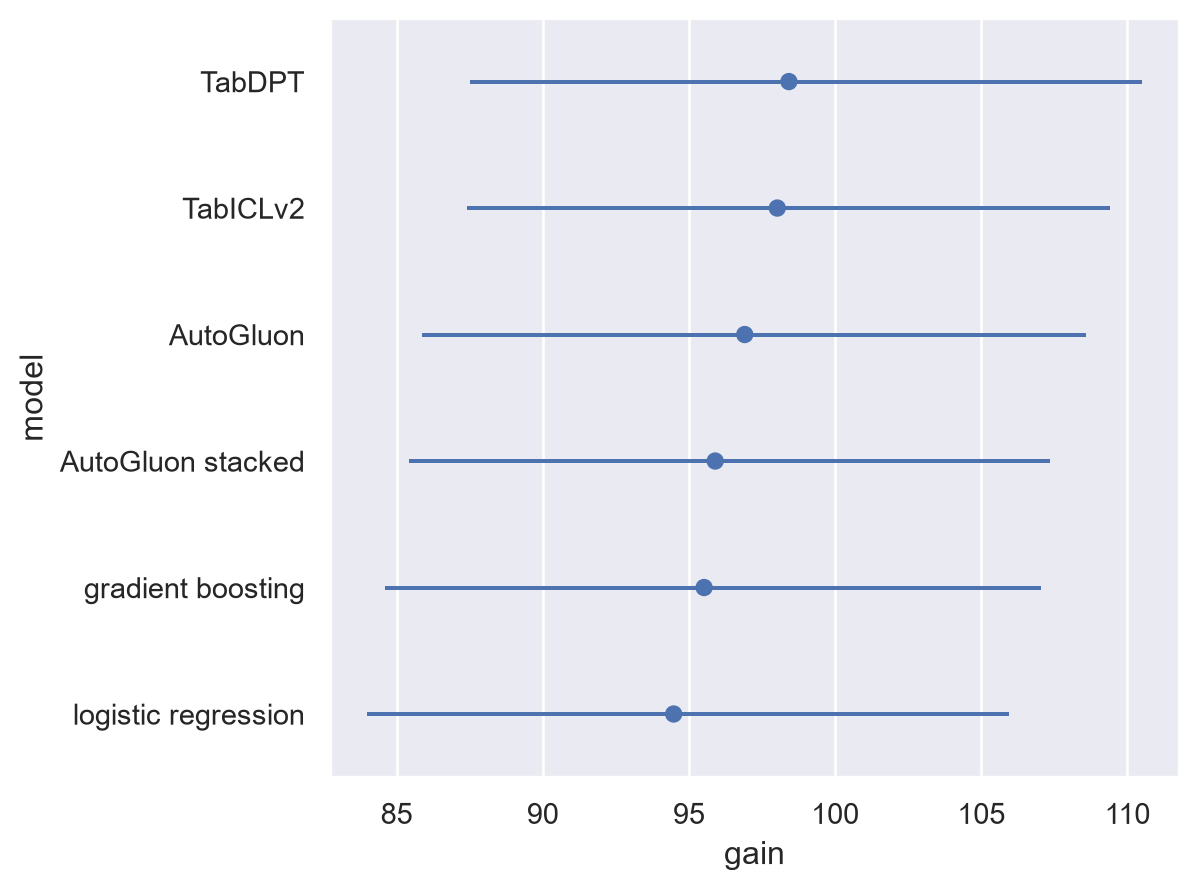

In [9]:
rng = np.random.default_rng(42)
boot_indices = rng.integers(0, len(y_test), size=(1000, len(y_test)))

def gain(y_pred, idx):
  return -cost_metric(y_test[idx], y_pred[idx], LoanAmount_test[idx])

gains, boots = {}, {}
for name, proba in test_probas.items():
  y_pred = cost_predict_from_single_proba(np.asarray(proba), LoanAmount_test)
  gains[name] = gain(y_pred, np.arange(len(y_test)))
  boots[name] = np.array([gain(y_pred, idx) for idx in boot_indices])
best = max(gains, key=gains.get)
summary = pl.DataFrame([
    {'model': name, 'gain': gains[name], 'lower': np.quantile(boots[name], .025), 'upper': np.quantile(boots[name], .975),
     'difference with the best: lower': np.quantile(boots[name] - boots[best], .025),
     'difference with the best: upper': np.quantile(boots[name] - boots[best], .975),
     'fit time (s)': fit_times[name]}
    for name in gains]).sort('gain', descending=True)
print(summary)
so.Plot(summary, y='model', x='gain', xmin='lower', xmax='upper').add(so.Range()).add(so.Dot())

**Conclusion** The observed gains range from $94.5$ to $98.4$ on the same 1000 loans. TabDPT ranks first in this sample. Selecting that reference on the test set makes the paired intervals exploratory. Their endpoints do not establish which methods outperform the selected winner. Fit times ranged from less than a second for logistic regression to several minutes for AutoGluon.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.